# Reviwer 4

In [ ]:
import pandas as pd
from scipy.stats import chi2_contingency, fisher_exact

# Variables to assess for missingness
variables = [
    'Age',
    'Sex',
    'CD4',
    'V-LOAD',
    'ALB',
    'BILT',
    'ALP',
    'AST',
    'ALT'
]

results = []

# Loop through each variable
for var in variables:
    
    # Create missingness indicator
    missing = df_ALP[var].isna()
    
    # Create 2x2 table:
    # rows = HBsAg status
    # columns = missing / not missing
    table = pd.crosstab(df_ALP['HBsAg_Status'], missing)
    
    # Make sure both False and True columns exist
    table = table.reindex(columns=[False, True], fill_value=0)
    table = table.reindex(index=[0, 1], fill_value=0)
    
    # Counts
    negative_total = (df_ALP['HBsAg_Status'] == 0).sum()
    positive_total = (df_ALP['HBsAg_Status'] == 1).sum()
    
    negative_missing = table.loc[0, True]
    positive_missing = table.loc[1, True]
    
    # Percentages
    negative_pct = (negative_missing / negative_total) * 100
    positive_pct = (positive_missing / positive_total) * 100
    
    # Statistical test
    chi2, p_chi, dof, expected = chi2_contingency(table)
    
    # Use Fisher's exact test if expected cell count < 5
    if (expected < 5).any():
        _, p_value = fisher_exact(table)
        test_used = "Fisher's exact"
    else:
        p_value = p_chi
        test_used = "Chi-square"
    
    results.append({
        'Variable': var,
        'HBsAg Negative Missing n (%)': f'{negative_missing} ({negative_pct:.1f}%)',
        'HBsAg Positive Missing n (%)': f'{positive_missing} ({positive_pct:.1f}%)',
        'Statistical test': test_used,
        'P-value': p_value
    })

# Create final table
missingness_table = pd.DataFrame(results)

# Round p-values
missingness_table['P-value'] = missingness_table['P-value'].apply(
    lambda x: f'{x:.4f}' if x >= 0.0001 else '<0.0001'
)

# Display
print(missingness_table.to_string(index=False))

In [ ]:
import pandas as pd
from scipy.stats import chi2_contingency, fisher_exact
from openpyxl import load_workbook
from openpyxl.styles import Font, Alignment, Border, Side
from openpyxl.utils import get_column_letter

# ============================================================
# SUPPLEMENTARY TABLE S1: MISSINGNESS BY HBsAg STATUS
# ============================================================

# Load your final analytical dataset
# If df_ALP is already loaded in your notebook, you can skip this line.
df = pd.read_csv("dataset_ALP_removed.csv")

# Remove variables with >50% missingness, as in your analysis
columns_to_remove = ['GGT', 'K+', 'NA+', 'BILD']
df_ALP = df_ALP.drop(columns=columns_to_remove, errors='ignore').copy()

# Variables for the missingness analysis
variables = [
    'Age',
    'Sex',
    'CD4',
    'V-LOAD',
    'ALB',
    'BILT',
    'ALP',
    'AST',
    'ALT'
]

# Check that all required columns are present
required_columns = ['HBsAg_Status'] + variables
missing_columns = [col for col in required_columns if col not in df_ALP.columns]

if missing_columns:
    raise ValueError(f"These columns are missing from the dataset: {missing_columns}")

# Check HBsAg outcome counts
print("HBsAg Status counts:")
print(df_ALP['HBsAg_Status'].value_counts(dropna=False))
print()

# Ensure HBsAg_Status has no missing values
if df_ALP['HBsAg_Status'].isna().any():
    raise ValueError("HBsAg_Status contains missing values. Please resolve these before analysis.")

# Totals
negative_total = (df_ALP['HBsAg_Status'] == 0).sum()
positive_total = (df_ALP['HBsAg_Status'] == 1).sum()

print(f"HBsAg-negative patients: {negative_total}")
print(f"HBsAg-positive patients: {positive_total}")
print(f"Total patients: {len(df_ALP)}")
print()

results = []

for var in variables:

    # Missingness indicator
    missing = df_ALP[var].isna()

    # 2 × 2 table:
    # HBsAg status × missing/not missing
    table = pd.crosstab(df_ALP['HBsAg_Status'], missing)

    # Force consistent order:
    # False = observed, True = missing
    table = table.reindex(index=[0, 1], columns=[False, True], fill_value=0)

    # Missing counts
    negative_missing = int(table.loc[0, True])
    positive_missing = int(table.loc[1, True])

    # Missing percentages within each HBsAg group
    negative_pct = (negative_missing / negative_total) * 100
    positive_pct = (positive_missing / positive_total) * 100

    # Chi-square test
    chi2, p_chi, dof, expected = chi2_contingency(table)

    # Fisher's exact test when any expected cell count is <5
    if (expected < 5).any():
        odds_ratio, p_value = fisher_exact(table)
        test_used = "Fisher's exact"
    else:
        p_value = p_chi
        test_used = "Chi-square"

    results.append({
        'Variable': var,
        'HBsAg negative, Missing n': negative_missing,
        'HBsAg negative, Missing %': negative_pct,
        'HBsAg positive, Missing n': positive_missing,
        'HBsAg positive, Missing %': positive_pct,
        'Statistical test': test_used,
        'P-value': p_value
    })

# Create DataFrame
missingness_table = pd.DataFrame(results)

# Round percentages to one decimal place
missingness_table['HBsAg negative, Missing %'] = (
    missingness_table['HBsAg negative, Missing %'].round(1)
)

missingness_table['HBsAg positive, Missing %'] = (
    missingness_table['HBsAg positive, Missing %'].round(1)
)

# Format p-values for publication
def format_pvalue(p):
    if p < 0.0001:
        return '<0.0001'
    return f'{p:.4f}'

missingness_table['P-value'] = missingness_table['P-value'].apply(format_pvalue)

# ============================================================
# ADD OUTCOME INFORMATION
# ============================================================

# This confirms that the outcome itself has no missing values.
outcome_row = pd.DataFrame([{
    'Variable': 'HBsAg_Status (outcome)',
    'HBsAg negative, Missing n': 0,
    'HBsAg negative, Missing %': 0.0,
    'HBsAg positive, Missing n': 0,
    'HBsAg positive, Missing %': 0.0,
    'Statistical test': 'Not applicable',
    'P-value': 'Not applicable'
}])

# Keep predictor variables first and outcome last
missingness_table = pd.concat(
    [missingness_table, outcome_row],
    ignore_index=True
)

# ============================================================
# SAVE TO EXCEL
# ============================================================

output_file = "Supplementary_Table_S1_Missingness_by_HBsAg_Status.xlsx"

with pd.ExcelWriter(output_file, engine='openpyxl') as writer:

    # Main table
    missingness_table.to_excel(
        writer,
        sheet_name='Supplementary Table S1',
        index=False,
        startrow=3
    )

    # Add title and explanatory notes
    worksheet = writer.book['Supplementary Table S1']

    worksheet['A1'] = 'Supplementary Table S1. Missingness of included variables stratified by HBsAg status'
    worksheet['A2'] = (
        f'HBsAg-negative: n={negative_total}; '
        f'HBsAg-positive: n={positive_total}; '
        f'Total: n={len(df_ALP)}'
    )

    worksheet['A1'].font = Font(bold=True, size=12)
    worksheet['A2'].font = Font(italic=True, size=10)

    # Notes below the table
    note_row = len(missingness_table) + 6

    worksheet.cell(
        row=note_row,
        column=1,
        value=(
            'Note: Missing percentages were calculated within each HBsAg status group. '
            'The chi-square test was used when expected cell counts were adequate; '
            'Fisher’s exact test was used when any expected cell count was <5. '
            'Percentages are rounded to one decimal place.'
        )
    )

    worksheet.cell(
        row=note_row + 1,
        column=1,
        value=(
            'HBsAg_Status was the outcome variable and had no missing observations; '
            'therefore, a statistical comparison of outcome missingness was not applicable.'
        )
    )

    # ========================================================
    # FORMATTING
    # ========================================================

    # Merge title across all columns
    max_col = len(missingness_table.columns)
    worksheet.merge_cells(
        start_row=1,
        start_column=1,
        end_row=1,
        end_column=max_col
    )

    worksheet.merge_cells(
        start_row=2,
        start_column=1,
        end_row=2,
        end_column=max_col
    )

    # Header formatting
    header_row = 4

    for cell in worksheet[header_row]:
        cell.font = Font(bold=True)
        cell.alignment = Alignment(
            horizontal='center',
            vertical='center',
            wrap_text=True
        )

    # Body formatting
    for row in worksheet.iter_rows(
        min_row=header_row + 1,
        max_row=header_row + len(missingness_table),
        min_col=1,
        max_col=max_col
    ):
        for cell in row:
            cell.alignment = Alignment(
                horizontal='center',
                vertical='center',
                wrap_text=True
            )

    # Left-align variable names
    for row in range(header_row + 1, header_row + len(missingness_table) + 1):
        worksheet.cell(row=row, column=1).alignment = Alignment(
            horizontal='left',
            vertical='center'
        )

    # Thin borders
    thin_border = Border(
        left=Side(style='thin'),
        right=Side(style='thin'),
        top=Side(style='thin'),
        bottom=Side(style='thin')
    )

    for row in worksheet.iter_rows(
        min_row=header_row,
        max_row=header_row + len(missingness_table),
        min_col=1,
        max_col=max_col
    ):
        for cell in row:
            cell.border = thin_border

    # Column widths
    column_widths = {
        'A': 28,
        'B': 23,
        'C': 25,
        'D': 23,
        'E': 25,
        'F': 20,
        'G': 14
    }

    for column, width in column_widths.items():
        worksheet.column_dimensions[column].width = width

    # Row heights
    worksheet.row_dimensions[1].height = 24
    worksheet.row_dimensions[2].height = 20
    worksheet.row_dimensions[4].height = 42

    # Freeze header
    worksheet.freeze_panes = 'A5'

    # Print settings
    worksheet.sheet_properties.pageSetUpPr.fitToPage = True
    worksheet.page_setup.fitToWidth = 1
    worksheet.page_setup.fitToHeight = 0
    worksheet.page_setup.orientation = 'landscape'

print("Supplementary Table S1 created successfully.")
print(f"Saved as: {output_file}")
print()
print(missingness_table.to_string(index=False))


In [2]:
import pandas as pd



# Load the cleaned dataset
df_missingness = pd.read_csv("cleaned_dataset.csv")

# Create a separate copy for the Reviewer 4 missingness analysis
df_missingness = df_missingness.copy()

# Check the dataset
print("Dataset shape:", df_missingness.shape)
print(df_missingness.head())

Dataset shape: (634, 29)
    District Sex  Age  ART_Duration         Regimen   WBC   HGB   HCT    PLT  \
0  Rukungiri   M   60          3066  DTG/ATVr-based  1.10   7.8  22.4   81.0   
1     Wakiso   F   45          3436       DTG-based  1.80  12.1  34.6  251.0   
2    Mbarara   M   68           271       DTG-based  1.92  10.3  31.3  118.0   
3    Kampala   F   46          2098       DTG-based  2.00  11.9  34.6   84.0   
4    Kampala   F   55          1092       DTG-based  2.00  11.8  35.5  144.0   

    MCH  ...   ALB    V-LOAD    CD4    ALP    AST    ALT   GGT    NA+    K+  \
0  32.4  ...  3.74    4340.0   79.0   60.4   45.2   24.5   NaN  114.8  4.93   
1  26.6  ...  4.38      40.0    3.0   91.9  114.5  123.4   NaN    NaN   NaN   
2  27.6  ...  3.60  118698.0   58.0   82.1   30.4   13.2  18.2  129.8  3.98   
3  30.9  ...  3.56  555000.0  153.0  108.6   25.9   15.5   NaN  131.3  4.92   
4  30.0  ...   NaN      50.0  493.0    NaN   24.1   22.4   NaN    NaN   NaN   

   HBsAg_Status  
0

In [3]:
# Variables with >50% missingness
columns_to_remove = ['GGT', 'K+', 'NA+', 'BILD']

# Remove them from the copy
df_missingness = df_missingness.drop(
    columns=columns_to_remove,
    errors='ignore'
).copy()

# Check resulting dataset
print("Dataset shape after removing >50% missing variables:",
      df_missingness.shape)

print("\nRemaining columns:")
print(df_missingness.columns.tolist())

Dataset shape after removing >50% missing variables: (634, 25)

Remaining columns:
['District', 'Sex', 'Age', 'ART_Duration', 'Regimen', 'WBC', 'HGB', 'HCT', 'PLT', 'MCH', 'MCHC', 'MVC', 'NE#', 'LY#', 'RBC', 'RDW', 'CREA', 'BILT', 'ALB', 'V-LOAD', 'CD4', 'ALP', 'AST', 'ALT', 'HBsAg_Status']


In [4]:
# Calculate percentage missing for each variable
missing_percentage = df_missingness.isnull().mean() * 100

# Display variables with missing values only
missing_percentage = missing_percentage[missing_percentage > 0]

# Round to one decimal place
missing_percentage = missing_percentage.round(1)

# Sort from highest to lowest
missing_percentage = missing_percentage.sort_values(ascending=False)

print("Missingness before imputation:")
print(missing_percentage)

print(df_missingness.columns.tolist())

Missingness before imputation:
ALP       46.8
ALB       33.3
BILT      29.0
CD4       17.8
V-LOAD    14.5
AST       13.4
HGB        9.6
WBC        9.0
RDW        9.0
RBC        9.0
LY#        9.0
NE#        9.0
MVC        9.0
MCHC       9.0
MCH        9.0
PLT        9.0
HCT        9.0
CREA       7.1
ALT        5.8
dtype: float64
['District', 'Sex', 'Age', 'ART_Duration', 'Regimen', 'WBC', 'HGB', 'HCT', 'PLT', 'MCH', 'MCHC', 'MVC', 'NE#', 'LY#', 'RBC', 'RDW', 'CREA', 'BILT', 'ALB', 'V-LOAD', 'CD4', 'ALP', 'AST', 'ALT', 'HBsAg_Status']


# Chi-square test 

In [5]:
import pandas as pd
from scipy.stats import chi2_contingency, fisher_exact
from openpyxl import load_workbook
from openpyxl.styles import Font, Alignment, Border, Side
from openpyxl.utils import get_column_letter

# ============================================================
# 1. LOAD THE CLEANED DATASET
# ============================================================

df_missingness = pd.read_csv("cleaned_dataset.csv").copy()

print("Dataset shape:", df_missingness.shape)

# ============================================================
# 2. VARIABLES INCLUDED IN THE PRIMARY ANALYSIS
# ============================================================

variables = [
    'District',
    'Sex',
    'Age',
    'ART_Duration',
    'Regimen',
    'WBC',
    'HGB',
    'HCT',
    'PLT',
    'MCH',
    'MCHC',
    'MVC',
    'NE#',
    'LY#',
    'RBC',
    'RDW',
    'CREA',
    'BILT',
    'ALB',
    'V-LOAD',
    'CD4',
    'ALP',
    'AST',
    'ALT'
]

# Outcome
outcome = 'HBsAg_Status'

# Check that all variables exist
required_columns = variables + [outcome]

missing_columns = [
    col for col in required_columns
    if col not in df_missingness.columns
]

if missing_columns:
    raise ValueError(
        f"The following columns are missing from the dataset: "
        f"{missing_columns}"
    )

# ============================================================
# 3. CHECK HBsAg STATUS
# ============================================================

print("\nHBsAg Status distribution:")
print(df_missingness[outcome].value_counts(dropna=False))

# Check for missing outcome
if df_missingness[outcome].isna().any():
    raise ValueError(
        "HBsAg_Status contains missing values. "
        "Please resolve this before performing the analysis."
    )

negative_total = (df_missingness[outcome] == 0).sum()
positive_total = (df_missingness[outcome] == 1).sum()
total = len(df_missingness)

print("\nGroup sizes:")
print(f"HBsAg negative: {negative_total}")
print(f"HBsAg positive: {positive_total}")
print(f"Total: {total}")

# ============================================================
# 4. CALCULATE MISSINGNESS BY HBsAg STATUS
# ============================================================

results = []

for var in variables:

    # Create missingness indicator
    missing = df_missingness[var].isna()

    # Create 2 x 2 table
    # Rows: HBsAg status
    # Columns: observed / missing
    table = pd.crosstab(
        df_missingness[outcome],
        missing
    )

    # Make sure both HBsAg groups and both missingness categories exist
    table = table.reindex(
        index=[0, 1],
        columns=[False, True],
        fill_value=0
    )

    # Missing counts
    negative_missing = int(table.loc[0, True])
    positive_missing = int(table.loc[1, True])

    # Missing percentages within each HBsAg group
    negative_pct = (
        negative_missing / negative_total * 100
    )

    positive_pct = (
        positive_missing / positive_total * 100
    )

    # --------------------------------------------------------
    # Statistical test
    # --------------------------------------------------------

    # If there is no missingness in either group,
    # statistical comparison is not applicable.
    if negative_missing == 0 and positive_missing == 0:

        test_used = "Not applicable"
        p_value = None

    else:

        # Chi-square test first
        chi2, p_chi, dof, expected = chi2_contingency(table)

        # Fisher's exact test if any expected count < 5
        if (expected < 5).any():

            odds_ratio, p_value = fisher_exact(table)
            test_used = "Fisher's exact"

        else:

            p_value = p_chi
            test_used = "Chi-square"

    # Format p-value
    if p_value is None:
        p_value_display = "Not applicable"
    elif p_value < 0.0001:
        p_value_display = "<0.0001"
    else:
        p_value_display = f"{p_value:.4f}"

    # Store results
    results.append({
        'Variable': var,
        'HBsAg-negative, Missing n': negative_missing,
        'HBsAg-negative, Missing %': round(negative_pct, 1),
        'HBsAg-positive, Missing n': positive_missing,
        'HBsAg-positive, Missing %': round(positive_pct, 1),
        'Statistical test': test_used,
        'P-value': p_value_display
    })

# Convert to DataFrame
missingness_table = pd.DataFrame(results)

# ============================================================
# 5. DISPLAY TABLE
# ============================================================

print("\nSupplementary Table S1:")
print(missingness_table.to_string(index=False))

# ============================================================
# 6. SAVE AS EXCEL
# ============================================================

output_file = "Supplementary_Table_S1_Missingness_by_HBsAg_Status.xlsx"

with pd.ExcelWriter(
    output_file,
    engine='openpyxl'
) as writer:

    missingness_table.to_excel(
        writer,
        sheet_name='Supplementary Table S1',
        index=False,
        startrow=3
    )

    workbook = writer.book
    worksheet = workbook['Supplementary Table S1']

    # --------------------------------------------------------
    # Title
    # --------------------------------------------------------

    worksheet['A1'] = (
        'Supplementary Table S1. Missingness of included variables '
        'stratified by HBsAg status'
    )

    worksheet['A2'] = (
        f'HBsAg-negative: n={negative_total}; '
        f'HBsAg-positive: n={positive_total}; '
        f'Total: n={total}'
    )

    # Merge title and group information
    max_col = len(missingness_table.columns)

    worksheet.merge_cells(
        start_row=1,
        start_column=1,
        end_row=1,
        end_column=max_col
    )

    worksheet.merge_cells(
        start_row=2,
        start_column=1,
        end_row=2,
        end_column=max_col
    )

    worksheet['A1'].font = Font(
        bold=True,
        size=12
    )

    worksheet['A2'].font = Font(
        italic=True,
        size=10
    )

    # --------------------------------------------------------
    # Header formatting
    # --------------------------------------------------------

    header_row = 4

    for cell in worksheet[header_row]:

        cell.font = Font(bold=True)

        cell.alignment = Alignment(
            horizontal='center',
            vertical='center',
            wrap_text=True
        )

    # --------------------------------------------------------
    # Body formatting
    # --------------------------------------------------------

    for row in worksheet.iter_rows(
        min_row=5,
        max_row=4 + len(missingness_table),
        min_col=1,
        max_col=max_col
    ):

        for cell in row:

            cell.alignment = Alignment(
                horizontal='center',
                vertical='center',
                wrap_text=True
            )

    # Left-align variable names
    for row in range(
        5,
        5 + len(missingness_table)
    ):

        worksheet.cell(
            row=row,
            column=1
        ).alignment = Alignment(
            horizontal='left',
            vertical='center'
        )

    # --------------------------------------------------------
    # Borders
    # --------------------------------------------------------

    thin_border = Border(
        left=Side(style='thin'),
        right=Side(style='thin'),
        top=Side(style='thin'),
        bottom=Side(style='thin')
    )

    for row in worksheet.iter_rows(
        min_row=header_row,
        max_row=4 + len(missingness_table),
        min_col=1,
        max_col=max_col
    ):

        for cell in row:
            cell.border = thin_border

    # --------------------------------------------------------
    # Column widths
    # --------------------------------------------------------

    widths = {
        'A': 20,
        'B': 25,
        'C': 25,
        'D': 25,
        'E': 25,
        'F': 20,
        'G': 15
    }

    for column, width in widths.items():
        worksheet.column_dimensions[column].width = width

    # Row heights
    worksheet.row_dimensions[1].height = 30
    worksheet.row_dimensions[2].height = 22
    worksheet.row_dimensions[4].height = 45

    # Freeze the header
    worksheet.freeze_panes = 'A5'

    # --------------------------------------------------------
    # Page setup for manuscript supplementary material
    # --------------------------------------------------------

    worksheet.page_setup.orientation = 'landscape'
    worksheet.page_setup.fitToWidth = 1
    worksheet.page_setup.fitToHeight = 0

    worksheet.sheet_properties.pageSetUpPr.fitToPage = True

    # --------------------------------------------------------
    # Add table note
    # --------------------------------------------------------

    note_row = 5 + len(missingness_table) + 2

    worksheet.cell(
        row=note_row,
        column=1,
        value=(
            'Note: Missing percentages were calculated within each '
            'HBsAg status group. The chi-square test was used when '
            'expected cell counts were adequate; Fisher’s exact test '
            'was used when any expected cell count was <5. '
            'Percentages are rounded to one decimal place.'
        )
    )

    worksheet.merge_cells(
        start_row=note_row,
        start_column=1,
        end_row=note_row,
        end_column=max_col
    )

    worksheet.cell(
        row=note_row,
        column=1
    ).alignment = Alignment(
        wrap_text=True,
        vertical='top'
    )

    worksheet.cell(
        row=note_row + 1,
        column=1,
        value=(
            'HBsAg_Status was the outcome variable and had no missing '
            'observations; therefore, it was not included as a predictor '
            'in the missingness comparison.'
        )
    )

    worksheet.merge_cells(
        start_row=note_row + 1,
        start_column=1,
        end_row=note_row + 1,
        end_column=max_col
    )

    worksheet.cell(
        row=note_row + 1,
        column=1
    ).alignment = Alignment(
        wrap_text=True,
        vertical='top'
    )

print("\nExcel file created successfully:")
print(output_file)

Dataset shape: (634, 29)

HBsAg Status distribution:
HBsAg_Status
0    464
1    170
Name: count, dtype: int64

Group sizes:
HBsAg negative: 464
HBsAg positive: 170
Total: 634

Supplementary Table S1:
    Variable  HBsAg-negative, Missing n  HBsAg-negative, Missing %  HBsAg-positive, Missing n  HBsAg-positive, Missing % Statistical test        P-value
    District                          0                        0.0                          0                        0.0   Not applicable Not applicable
         Sex                          0                        0.0                          0                        0.0   Not applicable Not applicable
         Age                          0                        0.0                          0                        0.0   Not applicable Not applicable
ART_Duration                          0                        0.0                          0                        0.0   Not applicable Not applicable
     Regimen                       

# LR for Age, ALB, CD4 and outcome

In [6]:
import pandas as pd

# Load your cleaned dataset
df = pd.read_csv("cleaned_dataset.csv")

# Keep only the 3 requested predictors and the outcome
baseline_df = df[["Age", "CD4", "ALB", "HBsAg_Status"]].copy()

# Save as a separate dataset
baseline_df.to_csv("logistic_regression_baseline_dataset.csv", index=False)

# Check it
print(baseline_df.shape)
print(baseline_df.head())
print(baseline_df.isnull().sum())

(634, 4)
   Age    CD4   ALB  HBsAg_Status
0   60   79.0  3.74             0
1   45    3.0  4.38             0
2   68   58.0  3.60             0
3   46  153.0  3.56             0
4   55  493.0   NaN             1
Age               0
CD4             113
ALB             211
HBsAg_Status      0
dtype: int64


In [7]:
print(baseline_df.dtypes)

Age               int64
CD4             float64
ALB             float64
HBsAg_Status      int64
dtype: object


In [8]:
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    recall_score,
    confusion_matrix,
    matthews_corrcoef,
    brier_score_loss
)

# ============================================================
# 1. Prepare predictors and outcome
# ============================================================

X = baseline_df[["Age", "CD4", "ALB"]].copy()
y = baseline_df["HBsAg_Status"].astype(int)

print("Dataset shape:", X.shape)
print("Outcome distribution:")
print(y.value_counts())

# ============================================================
# 2. Define nested 5-fold CV
# ============================================================

SEED = 42

outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

inner_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

# ============================================================
# 3. Leakage-free pipeline
# ============================================================

pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        solver="liblinear",
        random_state=SEED
    ))
])

# ============================================================
# 4. Hyperparameter grid
# ============================================================

param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100]
}

# ============================================================
# 5. Storage
# ============================================================

fold_results = []

# Out-of-fold predicted probabilities
oof_prob = np.zeros(len(y))

# ============================================================
# 6. Nested CV
# ============================================================

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y), start=1
):

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    # Inner CV tuning happens ONLY on the training portion
    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring="roc_auc",
        cv=inner_cv,
        n_jobs=-1,
        refit=True
    )

    grid_search.fit(X_train, y_train)

    # Best model from inner CV
    best_model = grid_search.best_estimator_

    # Predictions on completely unseen outer fold
    y_prob = best_model.predict_proba(X_test)[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)

    # Save OOF predictions
    oof_prob[test_idx] = y_prob

    # Confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    specificity = tn / (tn + fp) if (tn + fp) > 0 else np.nan

    # Metrics
    auc = roc_auc_score(y_test, y_prob)
    accuracy = accuracy_score(y_test, y_pred)
    mcc = matthews_corrcoef(y_test, y_pred)

    fold_results.append({
        "Fold": fold,
        "AUC": auc,
        "Accuracy": accuracy,
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "MCC": mcc,
        "Best_C": grid_search.best_params_["model__C"]
    })

    print(
        f"Fold {fold}: "
        f"AUC={auc:.3f}, "
        f"Accuracy={accuracy:.3f}, "
        f"Sensitivity={sensitivity:.3f}, "
        f"Specificity={specificity:.3f}, "
        f"MCC={mcc:.3f}, "
        f"Best C={grid_search.best_params_['model__C']}"
    )

# ============================================================
# 7. Fold results
# ============================================================

results_df = pd.DataFrame(fold_results)

print("\nFold-level results:")
display(results_df)

# ============================================================
# 8. Mean and 95% CI
# ============================================================

metrics = [
    "AUC",
    "Accuracy",
    "Sensitivity",
    "Specificity",
    "MCC"
]

summary = []

for metric in metrics:

    values = results_df[metric].values

    mean = np.mean(values)
    sd = np.std(values, ddof=1)
    se = sd / np.sqrt(len(values))

    ci_lower = mean - 1.96 * se
    ci_upper = mean + 1.96 * se

    summary.append({
        "Metric": metric,
        "Mean": mean,
        "95% CI Lower": ci_lower,
        "95% CI Upper": ci_upper
    })

summary_df = pd.DataFrame(summary)

print("\nNested CV summary:")
display(summary_df)

Dataset shape: (634, 3)
Outcome distribution:
HBsAg_Status
0    464
1    170
Name: count, dtype: int64
Fold 1: AUC=0.648, Accuracy=0.669, Sensitivity=0.059, Specificity=0.892, MCC=-0.074, Best C=0.01
Fold 2: AUC=0.750, Accuracy=0.740, Sensitivity=0.118, Specificity=0.968, MCC=0.166, Best C=0.01
Fold 3: AUC=0.712, Accuracy=0.701, Sensitivity=0.029, Specificity=0.946, MCC=-0.051, Best C=0.01
Fold 4: AUC=0.794, Accuracy=0.740, Sensitivity=0.088, Specificity=0.978, MCC=0.152, Best C=0.01
Fold 5: AUC=0.621, Accuracy=0.659, Sensitivity=0.059, Specificity=0.880, MCC=-0.089, Best C=0.1

Fold-level results:


,Fold,AUC,Accuracy,Sensitivity,Specificity,MCC,Best_C
0,1,0.647849,0.669291,0.058824,0.892473,-0.073723,0.01
1,2,0.749684,0.740157,0.117647,0.967742,0.165670,0.01
2,3,0.711575,0.700787,0.029412,0.946237,-0.050821,0.01
3,4,0.794118,0.740157,0.088235,0.978495,0.151928,0.01
4,5,0.620524,0.658730,0.058824,0.880435,-0.088636,0.10



Nested CV summary:


,Metric,Mean,95% CI Lower,95% CI Upper
0,AUC,0.704750,0.642177,0.767323
1,Accuracy,0.701825,0.668288,0.735362
2,Sensitivity,0.070588,0.041194,0.099983
3,Specificity,0.933076,0.894227,0.971925
4,MCC,0.020884,-0.090183,0.131950


In [9]:
display(summary_df)

,Metric,Mean,95% CI Lower,95% CI Upper
0,AUC,0.704750,0.642177,0.767323
1,Accuracy,0.701825,0.668288,0.735362
2,Sensitivity,0.070588,0.041194,0.099983
3,Specificity,0.933076,0.894227,0.971925
4,MCC,0.020884,-0.090183,0.131950


# New LR code 

LOGISTIC REGRESSION BASELINE
Dataset shape: (634, 3)

Outcome distribution:
HBsAg_Status
0    464
1    170
Name: count, dtype: int64

Outcome proportions:
HBsAg_Status
0    0.731861
1    0.268139
Name: proportion, dtype: float64

--------------------------------------------------------------------------------
OUTER FOLD 1
--------------------------------------------------------------------------------
Accuracy    = 0.669
Precision   = 0.167
Sensitivity = 0.059
Specificity = 0.892
F1          = 0.087
MCC         = -0.074
ROC-AUC     = 0.648
Best C      = 0.01

--------------------------------------------------------------------------------
OUTER FOLD 2
--------------------------------------------------------------------------------
Accuracy    = 0.740
Precision   = 0.571
Sensitivity = 0.118
Specificity = 0.968
F1          = 0.195
MCC         = 0.166
ROC-AUC     = 0.750
Best C      = 0.01

--------------------------------------------------------------------------------
OUTER FOLD 3
-----

,Fold,Accuracy,Precision,Sensitivity,Specificity,F1,MCC,ROC_AUC,Best_C,TN,FP,FN,TP
0,1,0.669291,0.166667,0.058824,0.892473,0.086957,-0.073723,0.647849,0.01,83,10,32,2
1,2,0.740157,0.571429,0.117647,0.967742,0.195122,0.165670,0.749684,0.01,90,3,30,4
2,3,0.700787,0.166667,0.029412,0.946237,0.050000,-0.050821,0.711575,0.01,88,5,33,1
3,4,0.740157,0.600000,0.088235,0.978495,0.153846,0.151928,0.794118,0.01,91,2,31,3
4,5,0.658730,0.153846,0.058824,0.880435,0.085106,-0.088636,0.620524,0.10,81,11,32,2



LOGISTIC REGRESSION NESTED-CV PERFORMANCE


,Metric,Point Estimate,95% CI Lower,95% CI Upper,Fold Mean
0,Accuracy,0.702,0.668,0.735,0.702
1,Precision,0.279,0.128,0.535,0.332
2,Sensitivity,0.071,0.041,0.100,0.071
3,Specificity,0.933,0.894,0.972,0.933
4,F1,0.113,0.063,0.166,0.114
5,MCC,0.007,-0.090,0.132,0.021
6,ROC_AUC,0.671,0.642,0.767,0.705



LOGISTIC REGRESSION CALIBRATION
Brier score = 0.1924


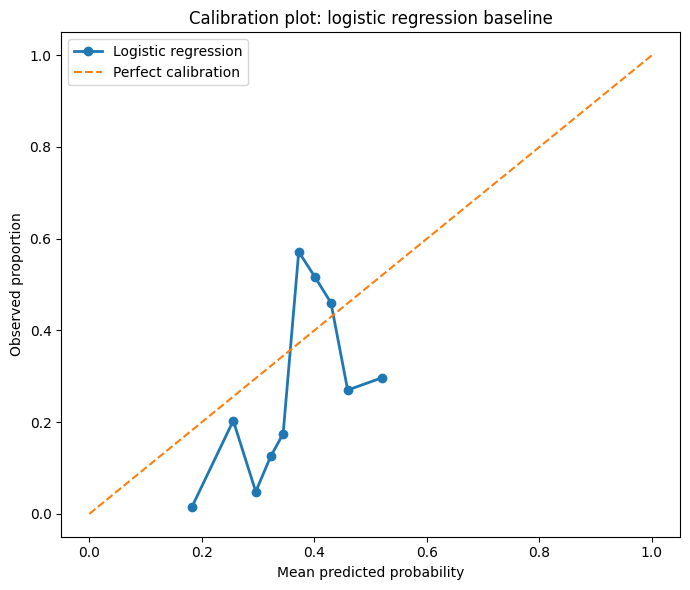

Calibration intercept = -0.199
Calibration slope = 1.476

Best C selected in each outer fold:
[0.01, 0.01, 0.01, 0.01, 0.1]

Most frequently selected C: 0.01

TABLE 2-READY LOGISTIC REGRESSION ROW


,Model,Accuracy,Precision,Sensitivity,Specificity,F1 Score,MCC,ROC-AUC
0,Logistic regression (Age + CD4 + ALB),0.702 (0.668–0.735),0.279 (0.128–0.535),0.071 (0.041–0.100),0.933 (0.894–0.972),0.113 (0.063–0.166),0.007 (-0.090–0.132),0.671 (0.642–0.767)


In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    matthews_corrcoef,
    brier_score_loss
)

from sklearn.calibration import calibration_curve


# ============================================================
# 1. PREPARE PREDICTORS AND OUTCOME
# ============================================================

baseline_features = ["Age", "CD4", "ALB"]

X = baseline_df[baseline_features].copy()
y = baseline_df["HBsAg_Status"].astype(int)

print("=" * 80)
print("LOGISTIC REGRESSION BASELINE")
print("=" * 80)

print("Dataset shape:", X.shape)

print("\nOutcome distribution:")
print(y.value_counts())

print("\nOutcome proportions:")
print(y.value_counts(normalize=True))


# ============================================================
# 2. NESTED 5-FOLD CROSS-VALIDATION
# ============================================================

SEED = 42

outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

inner_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)


# ============================================================
# 3. LEAKAGE-FREE PIPELINE
# ============================================================

pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),

    (
        "scaler",
        StandardScaler()
    ),

    (
        "model",
        LogisticRegression(
            max_iter=5000,
            solver="liblinear",
            random_state=SEED
        )
    )
])


# ============================================================
# 4. HYPERPARAMETER GRID
# ============================================================

param_grid = {
    "model__C": [
        0.01,
        0.1,
        1,
        10,
        100
    ]
}


# ============================================================
# 5. STORAGE
# ============================================================

fold_results = []

# Out-of-fold probabilities
oof_prob = np.zeros(len(y))

# Out-of-fold class predictions
oof_pred = np.zeros(len(y), dtype=int)

# Store best C from each outer fold
best_C_values = []


# ============================================================
# 6. NESTED CROSS-VALIDATION
# ============================================================

for fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y),
    start=1
):

    print("\n" + "-" * 80)
    print(f"OUTER FOLD {fold}")
    print("-" * 80)

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]


    # --------------------------------------------------------
    # INNER CV HYPERPARAMETER TUNING
    # --------------------------------------------------------

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,

        # ROC-AUC is used for tuning the logistic model.
        # The final model comparison remains based on MCC.
        scoring="roc_auc",

        cv=inner_cv,
        n_jobs=-1,
        refit=True
    )

    grid_search.fit(X_train, y_train)

    best_model = grid_search.best_estimator_

    best_C = grid_search.best_params_["model__C"]

    best_C_values.append(best_C)


    # --------------------------------------------------------
    # OUTER TEST PREDICTIONS
    # --------------------------------------------------------

    y_prob = best_model.predict_proba(X_test)[:, 1]

    y_pred = (y_prob >= 0.50).astype(int)


    # Save OOF predictions
    oof_prob[test_idx] = y_prob
    oof_pred[test_idx] = y_pred


    # --------------------------------------------------------
    # CONFUSION MATRIX
    # --------------------------------------------------------

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    ).ravel()


    # --------------------------------------------------------
    # METRICS
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    precision = precision_score(
        y_test,
        y_pred,
        zero_division=0
    )

    sensitivity = recall_score(
        y_test,
        y_pred,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    f1 = f1_score(
        y_test,
        y_pred,
        zero_division=0
    )

    mcc = matthews_corrcoef(
        y_test,
        y_pred
    )

    auc = roc_auc_score(
        y_test,
        y_prob
    )


    # --------------------------------------------------------
    # STORE RESULTS
    # --------------------------------------------------------

    fold_results.append({

        "Fold": fold,

        "Accuracy": accuracy,

        "Precision": precision,

        "Sensitivity": sensitivity,

        "Specificity": specificity,

        "F1": f1,

        "MCC": mcc,

        "ROC_AUC": auc,

        "Best_C": best_C,

        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })


    # --------------------------------------------------------
    # PRINT FOLD RESULTS
    # --------------------------------------------------------

    print(
        f"Accuracy    = {accuracy:.3f}\n"
        f"Precision   = {precision:.3f}\n"
        f"Sensitivity = {sensitivity:.3f}\n"
        f"Specificity = {specificity:.3f}\n"
        f"F1          = {f1:.3f}\n"
        f"MCC         = {mcc:.3f}\n"
        f"ROC-AUC     = {auc:.3f}\n"
        f"Best C      = {best_C}"
    )


# ============================================================
# 7. FOLD-LEVEL RESULTS
# ============================================================

results_df = pd.DataFrame(fold_results)

print("\n" + "=" * 80)
print("FOLD-LEVEL RESULTS")
print("=" * 80)

display(results_df)


# ============================================================
# 8. FUNCTION FOR 95% CI
# ============================================================

def mean_ci(values):

    values = np.asarray(values, dtype=float)

    mean = np.mean(values)

    sd = np.std(
        values,
        ddof=1
    )

    se = sd / np.sqrt(len(values))

    lower = mean - 1.96 * se
    upper = mean + 1.96 * se

    return mean, lower, upper


# ============================================================
# 9. POINT ESTIMATE + 95% CI
# ============================================================
#
# Point estimate:
#   pooled outer-fold OOF prediction
#
# CI:
#   mean +/- 1.96*SE across five outer folds
#
# This gives one final point estimate while retaining
# fold-to-fold uncertainty.
# ============================================================

metric_names = [
    "Accuracy",
    "Precision",
    "Sensitivity",
    "Specificity",
    "F1",
    "MCC",
    "ROC_AUC"
]

summary_rows = []

for metric in metric_names:

    # --------------------------------------------------------
    # POOLED OUT-OF-FOLD POINT ESTIMATE
    # --------------------------------------------------------

    if metric == "Accuracy":

        point_estimate = accuracy_score(
            y,
            oof_pred
        )

    elif metric == "Precision":

        point_estimate = precision_score(
            y,
            oof_pred,
            zero_division=0
        )

    elif metric == "Sensitivity":

        point_estimate = recall_score(
            y,
            oof_pred,
            zero_division=0
        )

    elif metric == "Specificity":

        tn, fp, fn, tp = confusion_matrix(
            y,
            oof_pred,
            labels=[0, 1]
        ).ravel()

        point_estimate = (
            tn / (tn + fp)
        )

    elif metric == "F1":

        point_estimate = f1_score(
            y,
            oof_pred,
            zero_division=0
        )

    elif metric == "MCC":

        point_estimate = matthews_corrcoef(
            y,
            oof_pred
        )

    elif metric == "ROC_AUC":

        point_estimate = roc_auc_score(
            y,
            oof_prob
        )


    # --------------------------------------------------------
    # 95% CI FROM OUTER FOLDS
    # --------------------------------------------------------

    fold_mean, ci_lower, ci_upper = mean_ci(
        results_df[metric]
    )


    summary_rows.append({

        "Metric": metric,

        "Point Estimate": point_estimate,

        "95% CI Lower": ci_lower,

        "95% CI Upper": ci_upper,

        "Fold Mean": fold_mean
    })


summary_df = pd.DataFrame(
    summary_rows
)


# ============================================================
# 10. DISPLAY SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("LOGISTIC REGRESSION NESTED-CV PERFORMANCE")
print("=" * 80)

display(
    summary_df.style.format({
        "Point Estimate": "{:.3f}",
        "95% CI Lower": "{:.3f}",
        "95% CI Upper": "{:.3f}",
        "Fold Mean": "{:.3f}"
    })
)


# ============================================================
# 11. BRIER SCORE
# ============================================================

brier_score = brier_score_loss(
    y,
    oof_prob
)

print("\n" + "=" * 80)
print("LOGISTIC REGRESSION CALIBRATION")
print("=" * 80)

print(
    f"Brier score = {brier_score:.4f}"
)


# ============================================================
# 12. CALIBRATION CURVE
# ============================================================

prob_true, prob_pred = calibration_curve(
    y,
    oof_prob,
    n_bins=10,
    strategy="quantile"
)


plt.figure(figsize=(7, 6))

plt.plot(
    prob_pred,
    prob_true,
    marker="o",
    linewidth=2,
    label="Logistic regression"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel(
    "Mean predicted probability"
)

plt.ylabel(
    "Observed proportion"
)

plt.title(
    "Calibration plot: logistic regression baseline"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    "logistic_regression_baseline_calibration.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 13. CALIBRATION INTERCEPT AND SLOPE
# ============================================================

from scipy.special import logit

# Avoid infinite logits
p = np.clip(
    oof_prob,
    1e-6,
    1 - 1e-6
)

logit_pred = logit(p)

calibration_df = pd.DataFrame({
    "logit_pred": logit_pred,
    "Outcome": y.values
})


calibration_model = LogisticRegression(
    penalty=None,
    solver="lbfgs",
    max_iter=5000
)

calibration_model.fit(
    calibration_df[["logit_pred"]],
    calibration_df["Outcome"]
)

calibration_intercept = (
    calibration_model.intercept_[0]
)

calibration_slope = (
    calibration_model.coef_[0][0]
)


print(
    f"Calibration intercept = "
    f"{calibration_intercept:.3f}"
)

print(
    f"Calibration slope = "
    f"{calibration_slope:.3f}"
)


# ============================================================
# 14. BEST C ACROSS OUTER FOLDS
# ============================================================

print("\nBest C selected in each outer fold:")
print(best_C_values)

print(
    "\nMost frequently selected C:",
    pd.Series(best_C_values).mode().iloc[0]
)


# ============================================================
# 15. TABLE 2-READY ROW
# ============================================================

table2_row = {
    "Model":
        "Logistic regression (Age + CD4 + ALB)",

    "Accuracy":
        f"{summary_df.loc[summary_df['Metric']=='Accuracy', 'Point Estimate'].iloc[0]:.3f} "
        f"({summary_df.loc[summary_df['Metric']=='Accuracy', '95% CI Lower'].iloc[0]:.3f}–"
        f"{summary_df.loc[summary_df['Metric']=='Accuracy', '95% CI Upper'].iloc[0]:.3f})",

    "Precision":
        f"{summary_df.loc[summary_df['Metric']=='Precision', 'Point Estimate'].iloc[0]:.3f} "
        f"({summary_df.loc[summary_df['Metric']=='Precision', '95% CI Lower'].iloc[0]:.3f}–"
        f"{summary_df.loc[summary_df['Metric']=='Precision', '95% CI Upper'].iloc[0]:.3f})",

    "Sensitivity":
        f"{summary_df.loc[summary_df['Metric']=='Sensitivity', 'Point Estimate'].iloc[0]:.3f} "
        f"({summary_df.loc[summary_df['Metric']=='Sensitivity', '95% CI Lower'].iloc[0]:.3f}–"
        f"{summary_df.loc[summary_df['Metric']=='Sensitivity', '95% CI Upper'].iloc[0]:.3f})",

    "Specificity":
        f"{summary_df.loc[summary_df['Metric']=='Specificity', 'Point Estimate'].iloc[0]:.3f} "
        f"({summary_df.loc[summary_df['Metric']=='Specificity', '95% CI Lower'].iloc[0]:.3f}–"
        f"{summary_df.loc[summary_df['Metric']=='Specificity', '95% CI Upper'].iloc[0]:.3f})",

    "F1 Score":
        f"{summary_df.loc[summary_df['Metric']=='F1', 'Point Estimate'].iloc[0]:.3f} "
        f"({summary_df.loc[summary_df['Metric']=='F1', '95% CI Lower'].iloc[0]:.3f}–"
        f"{summary_df.loc[summary_df['Metric']=='F1', '95% CI Upper'].iloc[0]:.3f})",

    "MCC":
        f"{summary_df.loc[summary_df['Metric']=='MCC', 'Point Estimate'].iloc[0]:.3f} "
        f"({summary_df.loc[summary_df['Metric']=='MCC', '95% CI Lower'].iloc[0]:.3f}–"
        f"{summary_df.loc[summary_df['Metric']=='MCC', '95% CI Upper'].iloc[0]:.3f})",

    "ROC-AUC":
        f"{summary_df.loc[summary_df['Metric']=='ROC_AUC', 'Point Estimate'].iloc[0]:.3f} "
        f"({summary_df.loc[summary_df['Metric']=='ROC_AUC', '95% CI Lower'].iloc[0]:.3f}–"
        f"{summary_df.loc[summary_df['Metric']=='ROC_AUC', '95% CI Upper'].iloc[0]:.3f})"
}

table2_df = pd.DataFrame([table2_row])

print("\n" + "=" * 80)
print("TABLE 2-READY LOGISTIC REGRESSION ROW")
print("=" * 80)

display(table2_df)

In [11]:
from sklearn.metrics import brier_score_loss

brier = brier_score_loss(y, oof_prob)

print(f"Brier score: {brier:.4f}")

Brier score: 0.1924


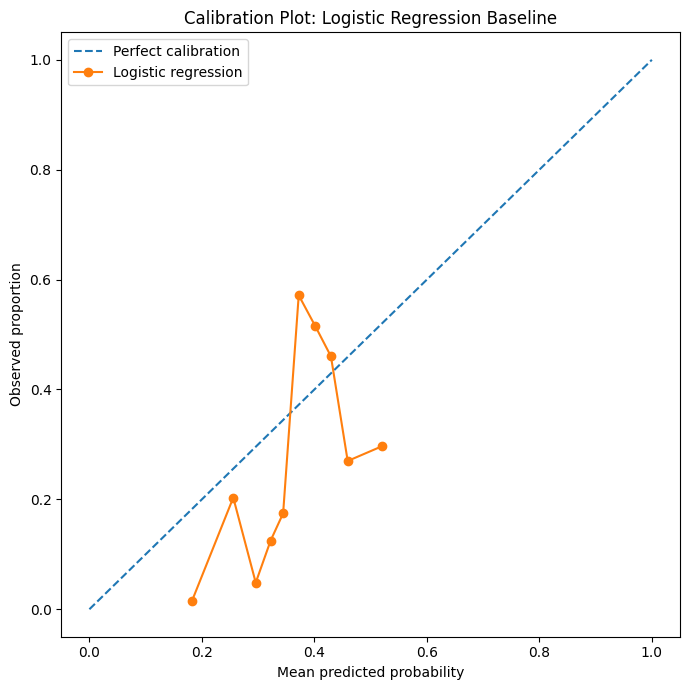

In [12]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

prob_true, prob_pred = calibration_curve(
    y,
    oof_prob,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(7, 7))

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.plot(
    prob_pred,
    prob_true,
    marker="o",
    label="Logistic regression"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Observed proportion")
plt.title("Calibration Plot: Logistic Regression Baseline")
plt.legend()
plt.tight_layout()
plt.show()